# Validación de modelo

In [1]:
import pandas as pd
import joblib
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Definiciones globales y funciones de transformación

%run ../Lib/pandas_options.py
%run ../Lib/define_constantes.py
%run ../Lib/fn_transformaciones.py

Fecha y Hora de ejecución de módulo: 2024-11-09 14:11:23


In [3]:
#  Cargar archivo para validación

archivo_validacion = f'{DIRECTORIO_RESULTADOS}/DATOSCCTV_VALIDACION_2024-11.csv'

df_cctv_validacion = pd.read_csv(archivo_validacion, usecols=['IPID', 'CALIFICACION', 'FECHA_CALIFICACION'])

print(df_cctv_validacion.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   IPID                150 non-null    int64  
 1   CALIFICACION        150 non-null    float64
 2   FECHA_CALIFICACION  150 non-null    object 
dtypes: float64(1), int64(1), object(1)
memory usage: 3.6+ KB
None


In [7]:
# Cargar archivo de tramos

archivo_tramos = f'{DIRECTORIO_DATOS}/DATOSTRAMOS_2024-10.csv'
df_tramos = pd.read_csv(archivo_tramos, low_memory=False)

print(df_tramos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221024 entries, 0 to 221023
Data columns (total 79 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   G3E_STYLEI,N,10,0  221024 non-null  int64  
 1   G3E_FNO,N,10,0     221024 non-null  int64  
 2   G3E_CNO,N,10,0     221024 non-null  int64  
 3   G3E_FID,N,10,0     221024 non-null  int64  
 4   G3E_CID,N,5,0      221024 non-null  int64  
 5   G3E_ID,N,10,0      221024 non-null  int64  
 6   DIAMETRO,N,10,0    221024 non-null  int64  
 7   CAMARA_CAI,C,255   221024 non-null  object 
 8   CONEXIONES,C,255   199642 non-null  object 
 9   MATERIAL,C,255     220587 non-null  object 
 10  TUBERIA_EL,C,255   206776 non-null  object 
 11  VIDA_UTIL,N,5,0    207362 non-null  float64
 12  FABRICANTE,C,255   203489 non-null  object 
 13  TIPO_CIMEN,C,255   91060 non-null   object 
 14  TIPO_SUELO,C,255   72833 non-null   object 
 15  TIPO_RED,C,255     221024 non-null  object 
 16  PR

In [9]:
# Corregir nombres de columnas 

df_tramos.columns = [col.split(',')[0] for col in df_tramos.columns]
print(df_tramos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221024 entries, 0 to 221023
Data columns (total 79 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   G3E_STYLEI  221024 non-null  int64  
 1   G3E_FNO     221024 non-null  int64  
 2   G3E_CNO     221024 non-null  int64  
 3   G3E_FID     221024 non-null  int64  
 4   G3E_CID     221024 non-null  int64  
 5   G3E_ID      221024 non-null  int64  
 6   DIAMETRO    221024 non-null  int64  
 7   CAMARA_CAI  221024 non-null  object 
 8   CONEXIONES  199642 non-null  object 
 9   MATERIAL    220587 non-null  object 
 10  TUBERIA_EL  206776 non-null  object 
 11  VIDA_UTIL   207362 non-null  float64
 12  FABRICANTE  203489 non-null  object 
 13  TIPO_CIMEN  91060 non-null   object 
 14  TIPO_SUELO  72833 non-null   object 
 15  TIPO_RED    221024 non-null  object 
 16  PROF_BATEA  218241 non-null  float64
 17  PROF_BATE1  218048 non-null  float64
 18  COTA_BATEA  216747 non-null  float64
 19  CO

In [10]:
# Consolidar tramos de validacion

df_tramos_validacion = df_tramos.merge(df_cctv_validacion, on='IPID')
print(df_tramos_validacion.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 81 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   G3E_STYLEI          148 non-null    int64  
 1   G3E_FNO             148 non-null    int64  
 2   G3E_CNO             148 non-null    int64  
 3   G3E_FID             148 non-null    int64  
 4   G3E_CID             148 non-null    int64  
 5   G3E_ID              148 non-null    int64  
 6   DIAMETRO            148 non-null    int64  
 7   CAMARA_CAI          148 non-null    object 
 8   CONEXIONES          141 non-null    object 
 9   MATERIAL            148 non-null    object 
 10  TUBERIA_EL          148 non-null    object 
 11  VIDA_UTIL           144 non-null    float64
 12  FABRICANTE          148 non-null    object 
 13  TIPO_CIMEN          62 non-null     object 
 14  TIPO_SUELO          52 non-null     object 
 15  TIPO_RED            148 non-null    object 
 16  PROF_BAT

In [11]:
# Aplicar secuencia de transformaciones

df_validacion_preprocesados = tx_aplicar_transformaciones(df_tramos_validacion)

Aplicando transformación: Depurar datos nulos         ... Terminada.
Aplicando transformación: Convertir tipo de datos     ... Terminada.
Aplicando transformación: Validar rango de datos      ... Terminada.
Aplicando transformación: Unificar unidades a metros  ... Terminada.
Aplicando transformación: Reasignar arranque          ... Terminada.
Aplicando transformación: Reasignar tipo de agua      ... Terminada.
Aplicando transformación: Reasignar materiales        ... Terminada.
Aplicando transformación: Reasignar fabricantes       ... Terminada.
Aplicando transformación: Reasignar zonas             ... Terminada.
Aplicando transformación: Reasignar municipios        ... Terminada.
Aplicando transformación: Reasignar estados           ... Terminada.
Aplicando transformación: Agregar edad de tramos      ... Terminada.
Aplicando transformación: Aregar área de tramos       ... Terminada.
Aplicando transformación: Recalcular pendientes       ... Terminada.
Aplicando transformación: Binariza

In [12]:
print(df_validacion_preprocesados.info())
print('-'*80)
print(df_validacion_preprocesados.describe(include='all'))
print('-'*80)
display(df_validacion_preprocesados)
print('-'*80)

columnas_categoricas = list(df_validacion_preprocesados.select_dtypes(include=['object']).columns)
columnas_numericas = list(df_validacion_preprocesados.select_dtypes(include=['int', 'float']).columns)
for columna in columnas_categoricas:
    print('-' * 80)
    print(columna)
    print(df_validacion_preprocesados[columna].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DETERIORADO         148 non-null    bool   
 1   EDAD                148 non-null    float64
 2   DIAMETRO            148 non-null    float64
 3   LONGITUD            148 non-null    float64
 4   AREA                148 non-null    float64
 5   PROF_BATEA          148 non-null    float64
 6   PROF_BATE1          148 non-null    float64
 7   PENDIENTE           148 non-null    float64
 8   TIPO_AGUA           148 non-null    object 
 9   MATERIAL            148 non-null    object 
 10  FABRICANTE          148 non-null    object 
 11  ARRANQUE            148 non-null    bool   
 12  ZONA_SUR            148 non-null    bool   
 13  MUNICIPIO_MEDELLIN  148 non-null    bool   
 14  ESTADO_OPERACION    148 non-null    bool   
dtypes: bool(5), float64(7), object(3)
memory usage: 12.4+ KB


,DETERIORADO,EDAD,DIAMETRO,LONGITUD,AREA,PROF_BATEA,PROF_BATE1,PENDIENTE,TIPO_AGUA,MATERIAL,FABRICANTE,ARRANQUE,ZONA_SUR,MUNICIPIO_MEDELLIN,ESTADO_OPERACION
0,False,-1.074626,1.514794,-0.469049,0.267470,-0.298122,0.082125,-0.316227,LLUVIAS Y DESCARGAS,CONCRETO SIMPLE,OTROS,False,True,False,True
1,False,-0.579421,-0.420735,-0.348343,-0.420792,-0.012850,0.459006,-0.314901,LLUVIAS Y DESCARGAS,CONCRETO SIMPLE,OTROS,True,True,False,True
2,False,-1.094116,-0.697239,1.443951,0.361063,-0.973266,-0.141649,-0.334231,OTRAS,PVC,OTROS,True,True,False,True
3,False,-0.778696,-0.420735,-0.117905,-0.275130,-0.963757,-0.942523,-0.247711,LLUVIAS Y DESCARGAS,PVC,MEXICHEM COLOMBIA S.A.S.,True,True,False,True
4,False,-1.158155,-0.420735,-1.112080,-0.903555,-1.087375,-0.447865,-1.114579,LLUVIAS Y DESCARGAS,PVC,MEXICHEM COLOMBIA S.A.S.,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,False,-1.075687,0.132274,-0.467952,-0.277674,-0.098432,0.930109,-0.521430,COMBINADAS,CONCRETO SIMPLE,OTROS,False,False,False,True
144,False,-1.160144,1.514794,-0.996496,-0.532697,0.976093,0.199900,0.859483,LLUVIAS Y DESCARGAS,PVC,MEXICHEM COLOMBIA S.A.S.,False,False,False,True
145,False,-1.093984,-0.697239,-0.470878,-0.607238,0.329476,0.105680,-0.057880,OTRAS,PVC,MEXICHEM COLOMBIA S.A.S.,False,False,False,True
146,True,0.330378,-0.144231,-0.597801,-0.485530,-0.916211,-0.636306,-0.347171,COMBINADAS,CONCRETO SIMPLE,INDUSTRIAS DIQUE S.A.,False,False,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
TIPO_AGUA
TIPO_AGUA
COMBINADAS             56
OTRAS                  52
LLUVIAS Y DESCARGAS    40
Name: count, dtype: int64
--------------------------------------------------------------------------------
MATERIAL
MATERIAL
CONCRETO SIMPLE               95
PVC                           37
CONCRETO REFORZADO Y OTROS    16
Name: count, dtype: int64
--------------------------------------------------------------------------------
FABRICANTE
FABRICANTE
INDUSTRIAS DIQUE S.A.       88
OTROS                       31
MEXICHEM COLOMBIA S.A.S.    29
Name: count, dtype: int64


In [13]:
df_validacion_codificados = tx_codificar(df_validacion_preprocesados)
print(df_validacion_codificados.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   DETERIORADO                          148 non-null    bool   
 1   EDAD                                 148 non-null    float64
 2   DIAMETRO                             148 non-null    float64
 3   LONGITUD                             148 non-null    float64
 4   AREA                                 148 non-null    float64
 5   PROF_BATEA                           148 non-null    float64
 6   PROF_BATE1                           148 non-null    float64
 7   PENDIENTE                            148 non-null    float64
 8   ARRANQUE                             148 non-null    bool   
 9   ZONA_SUR                             148 non-null    bool   
 10  MUNICIPIO_MEDELLIN                   148 non-null    bool   
 11  ESTADO_OPERACION                

In [14]:
# Cargar modelo

archivo_modelo = f'{DIRECTORIO_MODELOS}/modelo.joblib'
modelo = joblib.load(archivo_modelo)
print(modelo)

LogisticRegression(C=5,
                   class_weight={False: 1,
                                 True: np.float64(1.2031437966156067)},
                   n_jobs=-1, solver='newton-cholesky')


In [15]:
# Cargar columnas

columnas_modelo = []
archivo_columnas = f'{DIRECTORIO_MODELOS}/COLUMNAS.txt'

with open(archivo_columnas, "r") as archivo:
    for linea in archivo:
        cadena = linea.strip()
        columnas_modelo.append(cadena)

print(columnas_modelo)


['EDAD', 'DIAMETRO', 'LONGITUD', 'AREA', 'PROF_BATEA', 'PROF_BATE1', 'PENDIENTE', 'ARRANQUE', 'ZONA_SUR', 'MUNICIPIO_MEDELLIN', 'ESTADO_OPERACION', 'TIPO_AGUA_COMBINADAS', 'TIPO_AGUA_LLUVIAS Y DESCARGAS', 'TIPO_AGUA_OTRAS', 'MATERIAL_CONCRETO REFORZADO Y OTROS', 'MATERIAL_CONCRETO SIMPLE', 'MATERIAL_PVC', 'FABRICANTE_INDUSTRIAS DIQUE S.A.', 'FABRICANTE_MEXICHEM COLOMBIA S.A.S.', 'FABRICANTE_OTROS']


In [16]:
# Seleccionar columnas

X_validacion = df_validacion_codificados.drop('DETERIORADO', axis='columns')
Y_validacion = df_validacion_codificados['DETERIORADO']

# Agregar columnas faltantes
for col in columnas_modelo:
    if col not in X_validacion.columns:
        print(f'Agregando {col}')
        X_validacion[col] = False

# Reordenar columnas
X_validacion = X_validacion[columnas_modelo]

print(X_validacion.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   EDAD                                 148 non-null    float64
 1   DIAMETRO                             148 non-null    float64
 2   LONGITUD                             148 non-null    float64
 3   AREA                                 148 non-null    float64
 4   PROF_BATEA                           148 non-null    float64
 5   PROF_BATE1                           148 non-null    float64
 6   PENDIENTE                            148 non-null    float64
 7   ARRANQUE                             148 non-null    bool   
 8   ZONA_SUR                             148 non-null    bool   
 9   MUNICIPIO_MEDELLIN                   148 non-null    bool   
 10  ESTADO_OPERACION                     148 non-null    bool   
 11  TIPO_AGUA_COMBINADAS            

In [17]:
# Efectuar predicción

y_pred = modelo.predict(X_validacion)

              precision    recall  f1-score   support

       False       0.82      0.64      0.72        83
        True       0.64      0.82      0.72        65

    accuracy                           0.72       148
   macro avg       0.73      0.73      0.72       148
weighted avg       0.74      0.72      0.72       148



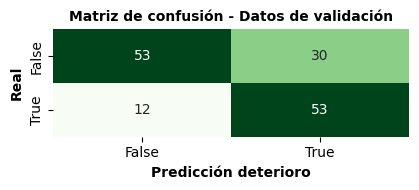

In [18]:
# Evaluar prediccion

print(classification_report(Y_validacion, y_pred))
conf_matrix = confusion_matrix(Y_validacion, y_pred)
class_names = [False, True]
plt.figure(figsize=(8, 2))
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens', cbar=False, xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción deterioro', fontweight='bold')
plt.ylabel('Real', fontweight='bold')
plt.title('Matriz de confusión - Datos de validación', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()